# Nanjing external validation with common CV and hold-out protocol

This notebook checks whether the main conclusions of Notebook 3 and the fixed model configurations of Notebook 4 remain observable in an independent fixed-camera dataset from Nanjing. It uses the same year-month-balanced, date-disjoint 80/20 development and common hold-out split as Notebook 4. Model comparison is based on five-fold date-grouped cross-validation within the development set, followed by one evaluation on the untouched common hold-out.

The supplied Nanjing images are already 224 × 224. The complete image is therefore treated as the fixed Nanjing ROI, while the feature definitions and model configurations are imported unchanged from the benchmark source code. No feature selection or hyperparameter search is performed on the common hold-out.

In [5]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'src').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'src').exists():
    raise FileNotFoundError('Run this notebook from the repository root or external validation directory.')
sys.path.insert(0, str(PROJECT_ROOT))

from src import config
from src.features import plots as features_plots
from src.features.evaluation import (
    balanced_month_group_split, evaluate_regression,
    get_feature_evaluation_models,
)
from src.models.benchmark import get_benchmark_models
from src.vision.handcrafted import extract_roi_features

DATA_DIR = PROJECT_ROOT / 'external validation' / 'Nanjing'
IMAGE_DIR = DATA_DIR / 'NJ_224'
LABEL_PATH = DATA_DIR / 'NJ_Image_AQI.xlsx'
ERA5_PATH = DATA_DIR / 'nanjing_era5_hourly.csv'
RESULTS_DIR = (
    PROJECT_ROOT
    / "external validation"
    / "results"
    / "nanjing_cv_holdout"
)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FEATURE_CACHE = PROJECT_ROOT / 'external validation' / 'results' / 'nanjing_handcrafted_features.csv'
RANDOM_STATE = 42
N_SPLITS = 5
FINAL_TEST_SIZE = 0.20
SPLIT_RANDOM_STATE = 24
TARGET = 'PM25'


## 1. Link labels and images

In [6]:
labels = pd.read_excel(LABEL_PATH)
labels.columns = [str(column).strip() for column in labels.columns]
required = {'Image Name', 'Year', 'Month', 'Day', 'Hour', 'PM2.5'}
missing = required - set(labels.columns)
if missing:
    raise ValueError(f'Missing required label columns: {sorted(missing)}')

# Work from the explicit date components; Finder modification dates are irrelevant.
labels['time_local'] = pd.to_datetime(dict(
    year=labels['Year'], month=labels['Month'], day=labels['Day'], hour=labels['Hour']
), errors='raise')
labels[TARGET] = pd.to_numeric(labels['PM2.5'], errors='coerce')
labels['image_stem'] = (labels['Image Name'].astype(str)
                        .str.extract(r'(\d{12})', expand=False))
image_lookup = {path.stem: path for path in IMAGE_DIR.glob('*.jpg')}
labels['image_path'] = labels['image_stem'].map(image_lookup)

quality_counts = {'Raw label rows': len(labels)}
quality_counts['Missing PM2.5'] = int(labels[TARGET].isna().sum())
quality_counts['Invalid PM2.5'] = int((labels[TARGET].notna() & ~labels[TARGET].between(0, 500)).sum())
quality_counts['Missing image link'] = int(labels['image_path'].isna().sum())

# Keep only the target used by the Milan benchmark; AQI, AQL, and PM10 are discarded.
validation = labels.loc[
    labels[TARGET].between(0, 500) & labels['image_path'].notna(),
    ['time_local', 'image_stem', 'image_path', TARGET],
].copy()
duplicate_count = int(validation['time_local'].duplicated().sum())
quality_counts['Duplicate timestamps'] = duplicate_count
validation = validation.sort_values('time_local').drop_duplicates('time_local')
if validation['time_local'].duplicated().any():
    raise ValueError('Duplicate Nanjing timestamps remain after linkage.')

quality_counts['JPEG files'] = len(image_lookup)
quality_counts['Label-image samples after QC'] = len(validation)
quality_counts['Independent dates after QC'] = validation['time_local'].dt.normalize().nunique()
coverage = pd.DataFrame({'Item': quality_counts.keys(), 'Value': quality_counts.values()})
display(coverage)
print('Time range:', validation['time_local'].min(), 'to', validation['time_local'].max())
print('PM2.5 range:', validation[TARGET].min(), 'to', validation[TARGET].max(), 'µg/m³')


,Item,Value
0,Raw label rows,2691
1,Missing PM2.5,0
2,Invalid PM2.5,0
3,Missing image link,0
4,Duplicate timestamps,0
5,JPEG files,2976
6,Label-image samples after QC,2691
7,Independent dates after QC,132


Time range: 2021-07-26 01:00:00 to 2021-12-31 15:00:00
PM2.5 range: 2 to 136 µg/m³


## 2. Extract the benchmark image features

The first run processes the linked images and writes a cache. Later runs reuse it.

In [7]:
NJ_ROI = {'top': 0, 'left': 0, 'height': 224, 'width': 224}

if FEATURE_CACHE.exists():
    image_features = pd.read_csv(
        FEATURE_CACHE, parse_dates=['time_local'], dtype={'image_stem': str}
    )
    print('Using cached features:', FEATURE_CACHE)
else:
    rows = []
    failures = []
    for record in validation[['time_local', 'image_stem', 'image_path']].itertuples(index=False):
        try:
            values = extract_roi_features(Path(record.image_path), roi=NJ_ROI)
            rows.append({'time_local': record.time_local, 'image_stem': record.image_stem, **values})
        except Exception as error:
            failures.append((record.image_stem, str(error)))
    image_features = pd.DataFrame(rows)
    image_features.to_csv(FEATURE_CACHE, index=False)
    print(f'Extracted {len(image_features):,} images; failures: {len(failures):,}')
    if failures:
        display(pd.DataFrame(failures[:10], columns=['Image', 'Reason']))

missing_features = set(config.IMAGE_FEATURES) - set(image_features.columns)
if missing_features:
    raise ValueError(f'Feature extraction is missing: {sorted(missing_features)}')

# Apply the same image validity rules used in Notebook 2. This also screens
# cached features, so rerunning extraction is not required.
finite_image_mask = np.isfinite(image_features[list(config.IMAGE_FEATURES)]).all(axis=1)
flat_image_mask = np.isclose(
    image_features[['R_std', 'G_std', 'B_std', 'contrast']], 0
).all(axis=1)
valid_image_mask = finite_image_mask & ~flat_image_mask
for column in ['R_roi', 'G_roi', 'B_roi']:
    valid_image_mask &= image_features[column].between(0, 255)
for column in ['R_std', 'G_std', 'B_std']:
    valid_image_mask &= image_features[column].ge(0)
for column in ['S_mean', 'V_mean', 'dark_pixel_ratio']:
    valid_image_mask &= image_features[column].between(0, 1)
invalid_image_count = int((~valid_image_mask).sum())
image_features = image_features.loc[valid_image_mask].copy()
print(f'Invalid/corrupt/flat images removed: {invalid_image_count:,}')


Using cached features: /Users/qingxuan/Desktop/webcam-pm25-benchmark/external validation/results/nanjing_handcrafted_features.csv
Invalid/corrupt/flat images removed: 0


## 3. Add temporal features and optional ERA5

ERA5 is optional so that the image and temporal checks can run immediately. To download it through the existing project pipeline, confirm the campus coordinates below, set `DOWNLOAD_ERA5 = True`, and run the next cell once. CDS credentials and accepted dataset terms are required. ERA5 timestamps are UTC; Nanjing image timestamps are converted from Asia/Shanghai before joining.

In [8]:
DOWNLOAD_ERA5 = False  # ERA5 CSV already exists; do not download again
NJ_LATITUDE = 32.11613
NJ_LONGITUDE = 118.91002

if DOWNLOAD_ERA5:
    from src.data.era5 import download_era5_data
    download_era5_data(
        lat=NJ_LATITUDE,
        lon=NJ_LONGITUDE,
        start_date=validation['time_local'].min().date(),
        end_date=validation['time_local'].max().date(),
        work_dir=DATA_DIR / 'era5_download',
        output_file=ERA5_PATH,
        pressure_area=[32.25, 118.75, 32.00, 119.00],
        overwrite=False,
    )
elif ERA5_PATH.exists():
    print('ERA5 file already available:', ERA5_PATH)
else:
    print('ERA5 download skipped. Set DOWNLOAD_ERA5=True when ready.')


ERA5 file already available: /Users/qingxuan/Desktop/webcam-pm25-benchmark/external validation/Nanjing/nanjing_era5_hourly.csv


In [9]:
df = validation.merge(image_features, on=['time_local', 'image_stem'], how='inner', validate='one_to_one')
print(f'PM2.5/image samples after image QC: {len(df):,}')
local = df['time_local']
df['hour'] = local.dt.hour
df['day'] = local.dt.day
df['weekday'] = local.dt.weekday
df['month'] = local.dt.month
df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)
df['weekday_sin'] = np.sin(2 * np.pi * df['weekday'] / 7)
df['weekday_cos'] = np.cos(2 * np.pi * df['weekday'] / 7)
df['month_sin'] = np.sin(2 * np.pi * (df['month'] - 1) / 12)
df['month_cos'] = np.cos(2 * np.pi * (df['month'] - 1) / 12)
df['is_weekend'] = (df['weekday'] >= 5).astype(int)
df['is_daytime'] = df['hour'].between(6, 18).astype(int)
df['date_group'] = local.dt.normalize()

era5_features = []
if ERA5_PATH.exists():
    era5 = pd.read_csv(ERA5_PATH)
    time_column = 'time' if 'time' in era5.columns else 'datetime'
    era5['time_utc'] = pd.to_datetime(era5[time_column], utc=True, errors='coerce').dt.tz_localize(None)
    era5 = era5.drop(columns=['CBH'], errors='ignore')
    era5 = era5.dropna(subset=['time_utc']).sort_values('time_utc').drop_duplicates('time_utc')

    # Notebook 2 physical-validity rules for ERA5. Invalid hours are removed,
    # not imputed, so every final row has an observed valid ERA5 record.
    era5_valid = pd.Series(True, index=era5.index)
    for column in ['RH']:
        if column in era5:
            era5_valid &= era5[column].between(0, 100)
    for column in ['TCC']:
        if column in era5:
            era5_valid &= era5[column].between(0, 1)
    for column in ['TP', 'WS10', 'BLH']:
        if column in era5:
            era5_valid &= era5[column].ge(0)
    era5_numeric = [column for column in config.ERA5_FEATURES if column in era5.columns]
    era5_valid &= np.isfinite(era5[era5_numeric]).all(axis=1)
    invalid_era5_count = int((~era5_valid).sum())
    era5 = era5.loc[era5_valid].copy()
    df['time_utc'] = (df['time_local'].dt.tz_localize('Asia/Shanghai')
                      .dt.tz_convert('UTC').dt.tz_localize(None))
    era5_features = [feature for feature in config.ERA5_FEATURES if feature in era5.columns]
    rows_before_era5 = len(df)
    df = df.merge(era5[['time_utc', *era5_features]], on='time_utc', how='inner', validate='one_to_one')
    print(f'Invalid/incomplete ERA5 hours removed: {invalid_era5_count:,}')
    print(f'Image timestamps without valid ERA5 match removed: {rows_before_era5 - len(df):,}')
    print(f'Joined {len(era5_features)} ERA5 variables:', era5_features)
else:
    print('ERA5 file not found; running image and temporal validation only.')

feature_sets = {
    'Image': list(config.IMAGE_FEATURES),
    'Image + Temporal': list(config.IMAGE_FEATURES + config.TEMPORAL_FEATURES),
}
if era5_features:
    feature_sets['Image + Temporal + ERA5'] = feature_sets['Image + Temporal'] + era5_features

required_columns = sorted(set(sum(feature_sets.values(), [])) | {TARGET, 'date_group'})
rows_before_complete_case = len(df)
model_df = df.dropna(subset=required_columns).reset_index(drop=True)
print(f'Incomplete final rows removed: {rows_before_complete_case - len(model_df):,}')

# Save a compact analysis-ready table. Image time remains the canonical timestamp.
final_columns = ['time_local', TARGET, *config.IMAGE_FEATURES, *config.TEMPORAL_FEATURES, *era5_features]
final_columns = list(dict.fromkeys(final_columns))
final_dataset = model_df[final_columns].rename(columns={'time_local': 'time'})
final_dataset.to_csv(RESULTS_DIR / 'nanjing_final_dataset.csv', index=False)
qc_summary = pd.DataFrame({
    'Check': [
        'Raw PM2.5 label rows', 'Missing PM2.5 removed',
        'Invalid PM2.5 removed', 'Missing image links removed',
        'Duplicate timestamps removed', 'Invalid image rows removed',
        'Invalid ERA5 hours in source', 'Image timestamps without ERA5 removed',
        'Incomplete final rows removed', 'Final complete samples',
    ],
    'Value': [
        len(labels), quality_counts['Missing PM2.5'], quality_counts['Invalid PM2.5'],
        quality_counts['Missing image link'], duplicate_count, invalid_image_count,
        invalid_era5_count if ERA5_PATH.exists() else 0,
        rows_before_era5 - len(df) if ERA5_PATH.exists() else 0,
        rows_before_complete_case - len(model_df), len(model_df),
    ],
})
qc_summary.to_csv(RESULTS_DIR / 'quality_control_summary.csv', index=False)
display(qc_summary)
print(f'Complete samples used: {len(model_df):,}; independent dates: {model_df.date_group.nunique():,}')


PM2.5/image samples after image QC: 2,691
Invalid/incomplete ERA5 hours removed: 0
Image timestamps without valid ERA5 match removed: 4
Joined 18 ERA5 variables: ['T2M', 'D2M', 'RH', 'U10', 'V10', 'SP', 'TP', 'BLH', 'TCC', 'WS10', 'GP_500', 'GP_850', 'T_500', 'T_850', 'U_500', 'U_850', 'V_500', 'V_850']
Incomplete final rows removed: 0


,Check,Value
0,Raw PM2.5 label rows,2691
1,Missing PM2.5 removed,0
2,Invalid PM2.5 removed,0
3,Missing image links removed,0
4,Duplicate timestamps removed,0
5,Invalid image rows removed,0
6,Invalid ERA5 hours in source,0
7,Image timestamps without ERA5 removed,4
8,Incomplete final rows removed,0
9,Final complete samples,2687


Complete samples used: 2,687; independent dates: 132


## 4. Common Development and Hold-Out Split

Complete calendar dates are allocated within every observed year-month using the same 80/20 split and split random state as Notebook 4. The development set is used for five-fold date-grouped cross-validation and model selection; the common hold-out remains untouched until the configurations are fixed.

In [10]:
model_df['year_month'] = model_df['time_local'].dt.to_period('M').astype(str)
development_df, final_test_df = balanced_month_group_split(
    model_df,
    time_column='time_local',
    test_size=FINAL_TEST_SIZE,
    random_state=SPLIT_RANDOM_STATE,
)

if development_df.empty or final_test_df.empty:
    raise ValueError('The development or common hold-out set is empty.')
if set(development_df['date_group']) & set(final_test_df['date_group']):
    raise ValueError('Development and hold-out sets contain shared dates.')
if len(development_df) + len(final_test_df) != len(model_df):
    raise ValueError('Split sample counts do not match the complete dataset.')

split_summary = pd.DataFrame([
    {
        'Subset': name,
        'Samples': len(subset),
        'Independent dates': subset['date_group'].nunique(),
        'Observed months': subset['year_month'].nunique(),
        'Percentage': len(subset) / len(model_df) * 100,
        'Mean PM2.5': subset[TARGET].mean(),
        'Median PM2.5': subset[TARGET].median(),
        'Maximum PM2.5': subset[TARGET].max(),
        'Samples >35': int((subset[TARGET] > 35).sum()),
    }
    for name, subset in {
        'Complete dataset': model_df,
        'Development set': development_df,
        'Common hold-out': final_test_df,
    }.items()
])
split_summary.to_csv(RESULTS_DIR / 'split_summary.csv', index=False)
display(split_summary.round(2))

,Subset,Samples,Independent dates,Observed months,Percentage,Mean PM2.5,Median PM2.5,Maximum PM2.5,Samples >35
0,Complete dataset,2687,132,6,100.00,26.43,22.0,136,686
1,Development set,2133,104,6,79.38,26.62,22.0,127,548
2,Common hold-out,554,28,6,20.62,25.70,22.0,136,138


## 5. PM2.5 Distribution and Monthly Coverage

The overall PM2.5 distribution and the corresponding monthly distributions are shown together to describe the concentration range, imbalance, and temporal coverage of the complete external analysis dataset.

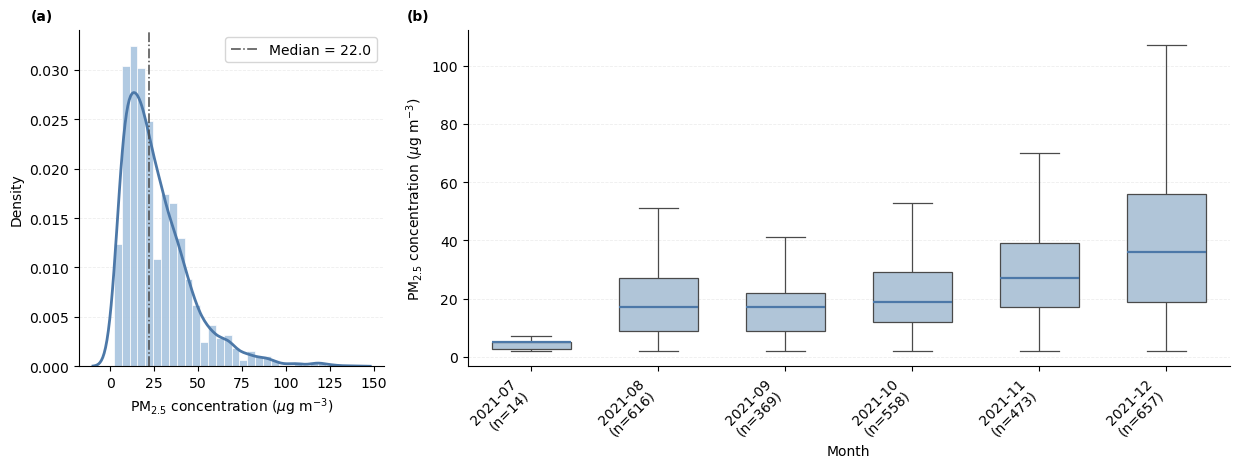

In [11]:
# Prepare the complete external dataset for monthly distribution plotting.
monthly_distribution_df = model_df.copy()
monthly_distribution_df['year_month'] = (
    pd.to_datetime(monthly_distribution_df['time_local'])
    .dt.to_period('M')
    .astype(str)
)

fig, axes = features_plots.plot_pm25_distribution_and_monthly_distributions(
    data=monthly_distribution_df,
    target=TARGET,
    output_path=(
        RESULTS_DIR / 'pm25_distribution_and_monthly_distributions.png'
    ),
)
plt.show()

## 6. Notebook 3 main check

The prespecified Ridge and Random Forest analytical models compare image-only features with temporal and, when available, ERA5 fusion. Five-fold date-grouped CV is calculated only within the development set, and each fixed configuration is then evaluated once on the common hold-out. MAE, RMSE, and R² remain the primary metrics; MAPE, SMAPE, and mean-normalised NRMSE are supplementary dimensionless measures.

In [12]:
def grouped_cv(model, features, data):
    splitter = GroupKFold(n_splits=N_SPLITS)
    fold_rows = []
    for fold, (train_idx, test_idx) in enumerate(
        splitter.split(data, groups=data['date_group']), start=1
    ):
        fitted = clone(model).fit(data.iloc[train_idx][features], data.iloc[train_idx][TARGET])
        observed = data.iloc[test_idx][TARGET]
        predicted = fitted.predict(data.iloc[test_idx][features])
        fold_rows.append({
            'Fold': fold,
            **evaluate_regression(observed, predicted),
        })
    return pd.DataFrame(fold_rows)

def fixed_holdout_evaluation(model, features, development_data, holdout_data):
    fitted = clone(model).fit(
        development_data[features], development_data[TARGET]
    )
    prediction = fitted.predict(holdout_data[features])
    return evaluate_regression(holdout_data[TARGET], prediction), prediction

n3_rows = []
for model_name, model in get_feature_evaluation_models(RANDOM_STATE).items():
    for feature_set_name, features in feature_sets.items():
        folds = grouped_cv(model, features, development_df)
        test_metrics, _ = fixed_holdout_evaluation(
            model, features, development_df, final_test_df
        )
        n3_rows.append({
            'Model': model_name, 'Feature Set': feature_set_name,
            'CV MAE': folds['MAE'].mean(), 'CV RMSE': folds['RMSE'].mean(),
            'CV R2': folds['R2'].mean(), 'CV R2 Std': folds['R2'].std(ddof=1),
            'CV MAPE': folds['MAPE'].mean(), 'CV MAPE Std': folds['MAPE'].std(ddof=1),
            'CV SMAPE': folds['SMAPE'].mean(), 'CV SMAPE Std': folds['SMAPE'].std(ddof=1),
            'CV NRMSE': folds['NRMSE'].mean(), 'CV NRMSE Std': folds['NRMSE'].std(ddof=1),
            'Test MAE': test_metrics['MAE'], 'Test RMSE': test_metrics['RMSE'],
            'Test R2': test_metrics['R2'], 'Test MAPE': test_metrics['MAPE'],
            'Test SMAPE': test_metrics['SMAPE'], 'Test NRMSE': test_metrics['NRMSE'],
        })
notebook3_results = pd.DataFrame(n3_rows)
notebook3_results.to_csv(RESULTS_DIR / 'notebook3_external_validation.csv', index=False)
display(notebook3_results.round(3))


,Model,Feature Set,CV MAE,CV RMSE,CV R2,CV R2 Std,CV MAPE,CV MAPE Std,CV SMAPE,CV SMAPE Std,CV NRMSE,CV NRMSE Std,Test MAE,Test RMSE,Test R2,Test MAPE,Test SMAPE,Test NRMSE
0,Ridge,Image,10.923,14.904,0.285,0.224,78.971,7.811,44.385,4.950,56.645,6.088,11.260,15.412,0.344,90.828,47.027,59.967
1,Ridge,Image + Temporal,11.258,15.172,0.248,0.264,80.420,10.732,45.875,3.948,57.932,7.555,11.311,15.405,0.344,95.533,47.329,59.941
2,Ridge,Image + Temporal + ERA5,10.385,13.990,0.363,0.220,71.861,13.835,45.329,9.322,53.434,7.604,10.117,13.590,0.490,73.108,46.573,52.878
3,Random Forest,Image,9.965,13.378,0.427,0.173,72.347,9.521,41.877,5.017,50.917,6.929,9.892,13.478,0.498,79.172,43.672,52.442
4,Random Forest,Image + Temporal,9.774,12.740,0.480,0.184,70.695,13.063,41.914,5.121,48.594,8.596,9.628,12.653,0.558,78.387,43.553,49.233
5,Random Forest,Image + Temporal + ERA5,8.862,11.791,0.550,0.175,61.282,15.824,38.483,4.937,45.020,8.472,9.533,13.105,0.526,71.094,43.415,50.990


## 7. Notebook 4 fixed-model check

All five benchmark model configurations are imported unchanged and use the richest available prespecified feature set. Models are ranked by development CV R², with RMSE and MAE as supporting criteria. The common hold-out is not used to select or adjust a model.

In [13]:
benchmark_feature_set = list(feature_sets)[-1]
benchmark_features = feature_sets[benchmark_feature_set]
n4_rows = []
for model_name, model in get_benchmark_models(RANDOM_STATE).items():
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        folds = grouped_cv(model, benchmark_features, development_df)
        test_metrics, _ = fixed_holdout_evaluation(
            model, benchmark_features, development_df, final_test_df
        )
    n4_rows.append({
        'Model': model_name, 'Feature Set': benchmark_feature_set,
        'CV MAE': folds['MAE'].mean(), 'CV RMSE': folds['RMSE'].mean(),
        'CV R2': folds['R2'].mean(), 'CV R2 Std': folds['R2'].std(ddof=1),
        'CV MAPE': folds['MAPE'].mean(), 'CV MAPE Std': folds['MAPE'].std(ddof=1),
        'CV SMAPE': folds['SMAPE'].mean(), 'CV SMAPE Std': folds['SMAPE'].std(ddof=1),
        'CV NRMSE': folds['NRMSE'].mean(), 'CV NRMSE Std': folds['NRMSE'].std(ddof=1),
        'Test MAE': test_metrics['MAE'], 'Test RMSE': test_metrics['RMSE'],
        'Test R2': test_metrics['R2'], 'Test MAPE': test_metrics['MAPE'],
        'Test SMAPE': test_metrics['SMAPE'], 'Test NRMSE': test_metrics['NRMSE'],
    })
notebook4_results = pd.DataFrame(n4_rows).sort_values(['CV R2', 'CV RMSE'], ascending=[False, True])
notebook4_results.to_csv(RESULTS_DIR / 'notebook4_external_validation.csv', index=False)
display(notebook4_results.round(3))


,Model,Feature Set,CV MAE,CV RMSE,CV R2,CV R2 Std,CV MAPE,CV MAPE Std,CV SMAPE,CV SMAPE Std,CV NRMSE,CV NRMSE Std,Test MAE,Test RMSE,Test R2,Test MAPE,Test SMAPE,Test NRMSE
3,Gradient Boosting,Image + Temporal + ERA5,8.638,11.653,0.555,0.166,56.804,10.663,37.760,4.589,44.581,7.253,8.822,12.056,0.598,65.975,41.850,46.910
2,Random Forest,Image + Temporal + ERA5,8.862,11.791,0.550,0.175,61.282,15.824,38.483,4.937,45.020,8.472,9.533,13.105,0.526,71.094,43.415,50.990
4,MLP,Image + Temporal + ERA5,9.037,11.982,0.510,0.233,59.351,12.472,42.491,4.596,46.155,10.096,9.722,12.914,0.539,69.707,45.886,50.248
0,Ridge,Image + Temporal + ERA5,10.385,13.990,0.363,0.220,71.861,13.835,45.329,9.322,53.434,7.604,10.117,13.590,0.490,73.108,46.573,52.878
1,Decision Tree,Image + Temporal + ERA5,10.952,14.407,0.278,0.431,72.962,22.948,45.395,6.873,55.718,15.212,11.210,14.641,0.408,75.183,47.892,56.968


## 8. Repeated Date-Disjoint Hold-Out Diagnostic

To quantify sensitivity to the particular dates assigned to the common hold-out, the fixed Gradient Boosting configuration is evaluated over 50 year-month-balanced, date-disjoint 80/20 splits. Only the split random state changes; the feature set, model configuration, test proportion, and metric definitions remain fixed. This diagnostic is not used for model selection. The empirical 2.5th and 97.5th percentiles describe variation across date allocations rather than a formal confidence interval for the underlying population.

In [14]:
# Repeated year-month-balanced, date-disjoint hold-out evaluation.
N_REPEATED_HOLDOUTS = 50
repeated_model = get_benchmark_models(RANDOM_STATE)['Gradient Boosting']
repeated_rows = []

for split_seed in range(N_REPEATED_HOLDOUTS):
    repeated_development, repeated_test = balanced_month_group_split(
        model_df,
        time_column='time_local',
        test_size=FINAL_TEST_SIZE,
        random_state=split_seed,
    )
    repeated_metrics, _ = fixed_holdout_evaluation(
        repeated_model, benchmark_features,
        repeated_development, repeated_test,
    )
    repeated_rows.append({
        'Split seed': split_seed,
        'Development samples': len(repeated_development),
        'Development dates': repeated_development['date_group'].nunique(),
        'Test samples': len(repeated_test),
        'Test dates': repeated_test['date_group'].nunique(),
        'Test mean PM2.5': repeated_test[TARGET].mean(),
        'Test maximum PM2.5': repeated_test[TARGET].max(),
        **repeated_metrics,
    })

repeated_holdout_results = pd.DataFrame(repeated_rows)
repeated_metric_columns = ['MAE', 'RMSE', 'R2', 'MAPE', 'SMAPE', 'NRMSE']
repeated_holdout_summary = pd.DataFrame([
    {
        'Metric': metric,
        'Mean': repeated_holdout_results[metric].mean(),
        'Std': repeated_holdout_results[metric].std(ddof=1),
        'Median': repeated_holdout_results[metric].median(),
        '2.5th percentile': repeated_holdout_results[metric].quantile(0.025),
        '97.5th percentile': repeated_holdout_results[metric].quantile(0.975),
    }
    for metric in repeated_metric_columns
])

current_gradient = notebook4_results.loc[
    notebook4_results['Model'].eq('Gradient Boosting')
].iloc[0]
current_metric_map = {
    'MAE': 'Test MAE', 'RMSE': 'Test RMSE', 'R2': 'Test R2',
    'MAPE': 'Test MAPE', 'SMAPE': 'Test SMAPE', 'NRMSE': 'Test NRMSE',
}
repeated_holdout_summary['Fixed split value'] = repeated_holdout_summary['Metric'].map(
    {metric: current_gradient[column] for metric, column in current_metric_map.items()}
)
repeated_holdout_summary['Fixed split numerical percentile'] = [
    (repeated_holdout_results[metric] <= current_gradient[current_metric_map[metric]]).mean() * 100
    for metric in repeated_holdout_summary['Metric']
]

repeated_holdout_results.to_csv(
    RESULTS_DIR / 'gradient_boosting_repeated_holdout_results.csv', index=False
)
repeated_holdout_summary.to_csv(
    RESULTS_DIR / 'gradient_boosting_repeated_holdout_summary.csv', index=False
)
display(repeated_holdout_summary.round(3))

,Metric,Mean,Std,Median,2.5th percentile,97.5th percentile,Fixed split value,Fixed split numerical percentile
0,MAE,8.298,0.751,8.293,6.913,9.688,8.822,78.0
1,RMSE,11.274,1.281,11.237,9.046,13.564,12.056,70.0
2,R2,0.638,0.097,0.637,0.414,0.782,0.598,30.0
3,MAPE,57.131,11.238,57.103,40.395,78.241,65.975,82.0
4,SMAPE,37.798,3.169,37.393,33.118,45.654,41.850,90.0
5,NRMSE,43.027,4.845,42.135,36.381,54.233,46.910,82.0


## 9. Common Hold-Out Concentration Diagnostic

Predictions from the development-CV-selected benchmark model on the untouched common hold-out are used to examine concentration-dependent errors under the same protocol as the Milan hold-out diagnostic.

,PM2.5 range,Samples,Dates,MAE,RMSE,Mean bias
0,≤20,267,20,8.534,10.765,6.874
1,20–35,149,24,6.098,8.157,-0.644
2,>35,138,13,12.319,16.954,-9.212


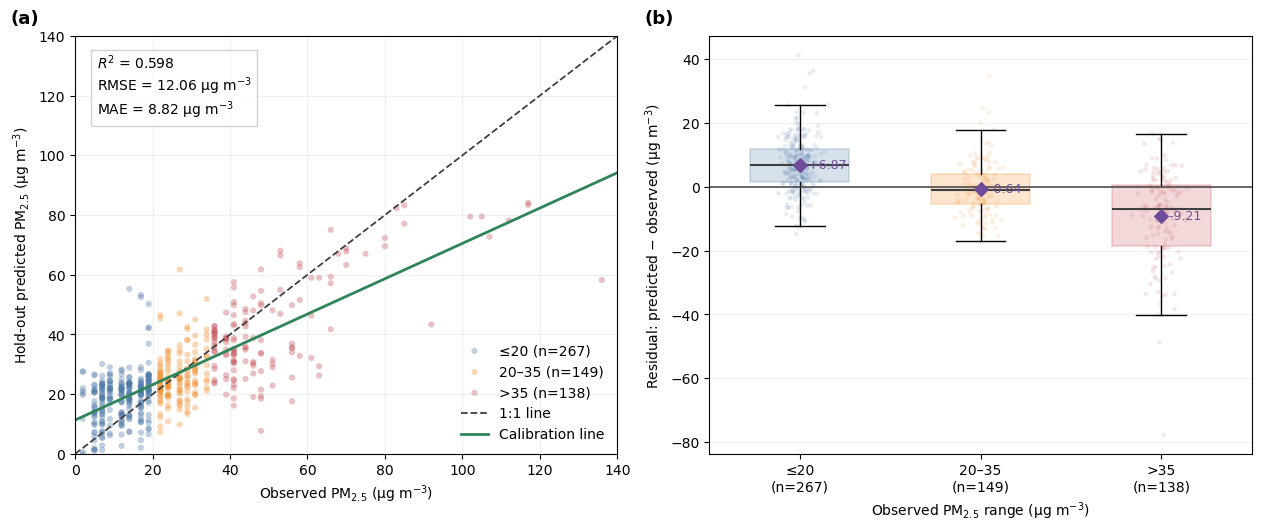

In [15]:
best_model_name = notebook4_results.iloc[0]['Model']
best_model = get_benchmark_models(RANDOM_STATE)[best_model_name]
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    best_holdout_metrics, best_holdout_prediction = fixed_holdout_evaluation(
        best_model, benchmark_features, development_df, final_test_df
    )

oof = pd.DataFrame({
    'time': final_test_df['time_local'].to_numpy(),
    'date': final_test_df['date_group'].to_numpy(),
    'observed': final_test_df[TARGET].to_numpy(),
    'predicted': best_holdout_prediction,
})
oof['residual'] = oof['predicted'] - oof['observed']
range_labels = ['≤20', '20–35', '>35']
oof['concentration_range'] = pd.cut(
    oof['observed'], bins=[-np.inf, 20, 35, np.inf], labels=range_labels
)

range_rows = []
for concentration_range, subset in oof.groupby('concentration_range', observed=True):
    range_rows.append({
        'PM2.5 range': concentration_range,
        'Samples': len(subset),
        'Dates': subset['date'].nunique(),
        'MAE': mean_absolute_error(subset['observed'], subset['predicted']),
        'RMSE': mean_squared_error(subset['observed'], subset['predicted']) ** 0.5,
        'Mean bias': subset['residual'].mean(),
    })
range_summary = pd.DataFrame(range_rows)
oof.to_csv(RESULTS_DIR / 'best_model_holdout_predictions.csv', index=False)
range_summary.to_csv(RESULTS_DIR / 'best_model_concentration_summary.csv', index=False)
display(range_summary.round(3))

mae = mean_absolute_error(oof['observed'], oof['predicted'])
rmse = mean_squared_error(oof['observed'], oof['predicted']) ** 0.5
r2 = r2_score(oof['observed'], oof['predicted'])
limit = np.ceil(max(oof['observed'].max(), oof['predicted'].max()) / 10) * 10
slope, intercept = np.polyfit(oof['observed'], oof['predicted'], 1)
line_x = np.linspace(0, limit, 200)
colours = {'≤20': '#4C78A8', '20–35': '#F28E2B', '>35': '#C44E52'}

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2), constrained_layout=True)
ax = axes[0]
for label in range_labels:
    subset = oof[oof['concentration_range'] == label]
    ax.scatter(
        subset['observed'], subset['predicted'], s=20, alpha=0.35,
        color=colours[label], edgecolor='none', label=f'{label} (n={len(subset):,})'
    )
ax.plot(line_x, line_x, '--', color='0.25', linewidth=1.3, label='1:1 line')
ax.plot(line_x, slope * line_x + intercept, color='#2F855A', linewidth=2, label='Calibration line')
ax.set(xlim=(0, limit), ylim=(0, limit), xlabel='Observed PM$_{2.5}$ (µg m$^{-3}$)',
       ylabel='Hold-out predicted PM$_{2.5}$ (µg m$^{-3}$)')
ax.text(
    0.04, 0.96, f'$R^2$ = {r2:.3f}\nRMSE = {rmse:.2f} µg m$^{{-3}}$\nMAE = {mae:.2f} µg m$^{{-3}}$',
    transform=ax.transAxes, va='top', bbox={'facecolor': 'white', 'edgecolor': '0.8', 'alpha': 0.9}
)
ax.legend(frameon=False, loc='lower right')
ax.grid(alpha=0.18)
ax.text(-0.12, 1.03, '(a)', transform=ax.transAxes, fontsize=13, fontweight='bold')

ax = axes[1]
range_data = [oof.loc[oof['concentration_range'] == label, 'residual'].to_numpy() for label in range_labels]
box = ax.boxplot(range_data, patch_artist=True, widths=0.55, showfliers=False)
for patch, label in zip(box['boxes'], range_labels):
    patch.set(facecolor=colours[label], alpha=0.22, edgecolor=colours[label], linewidth=1.3)
for median in box['medians']:
    median.set(color='0.25', linewidth=1.5)
rng = np.random.default_rng(RANDOM_STATE)
for position, (label, values) in enumerate(zip(range_labels, range_data), start=1):
    jitter = rng.normal(position, 0.055, size=len(values))
    ax.scatter(jitter, values, s=11, alpha=0.13, color=colours[label], edgecolor='none')
    mean_bias = values.mean()
    ax.scatter(position, mean_bias, marker='D', s=48, color='#6F4C9B', zorder=4)
    ax.text(position, mean_bias, f'  {mean_bias:+.2f}', va='center', color='#6F4C9B', fontsize=9)
ax.axhline(0, color='0.25', linewidth=1.1)
ax.set_xticks(range(1, 4), [f'{label}\n(n={len(values):,})' for label, values in zip(range_labels, range_data)])
ax.set(xlabel='Observed PM$_{2.5}$ range (µg m$^{-3}$)',
       ylabel='Residual: predicted − observed (µg m$^{-3}$)')
ax.grid(axis='y', alpha=0.18)
ax.text(-0.12, 1.03, '(b)', transform=ax.transAxes, fontsize=13, fontweight='bold')

figure_path = RESULTS_DIR / 'best_model_holdout_concentration_diagnostic.png'
fig.savefig(figure_path, dpi=300, bbox_inches='tight')
fig.savefig(figure_path.with_suffix('.pdf'), bbox_inches='tight')
plt.show()


## 10. Compact text summary for the thesis

In [16]:
image_rf = notebook3_results.query("Model == 'Random Forest' and `Feature Set` == 'Image'").iloc[0]
fusion_rf = notebook3_results.query("Model == 'Random Forest' and `Feature Set` == @benchmark_feature_set").iloc[0]
best = notebook4_results.iloc[0]
summary = (
    f'Supplementary external validation was conducted on {len(model_df):,} hourly observations '
    f'from an independent fixed surveillance camera using a year-month-balanced, date-disjoint '
    f'development and common hold-out split. Under development-set five-fold cross-validation, '
    f'the Random Forest '
    f'achieved R²={image_rf["CV R2"]:.3f} with image features alone and '
    f'R²={fusion_rf["CV R2"]:.3f} with {benchmark_feature_set.lower()} predictors. '
    f'Among the fixed Notebook 4 models, {best["Model"]} produced the strongest external '
    f'development-CV performance (MAE={best["CV MAE"]:.2f} µg/m³, RMSE={best["CV RMSE"]:.2f} µg/m³, '
    f'R²={best["CV R2"]:.3f}, MAPE={best["CV MAPE"]:.2f}%, '
    f'SMAPE={best["CV SMAPE"]:.2f}%, and NRMSE={best["CV NRMSE"]:.2f}%). '
    f'On the untouched common hold-out, the same model obtained MAE={best["Test MAE"]:.2f} µg/m³, '
    f'RMSE={best["Test RMSE"]:.2f} µg/m³, R²={best["Test R2"]:.3f}, '
    f'MAPE={best["Test MAPE"]:.2f}%, SMAPE={best["Test SMAPE"]:.2f}%, '
    f'and NRMSE={best["Test NRMSE"]:.2f}%.'
)
print(summary)
(RESULTS_DIR / 'thesis_summary.txt').write_text(summary + '\n', encoding='utf-8')


Supplementary external validation was conducted on 2,687 hourly observations from an independent fixed surveillance camera using a year-month-balanced, date-disjoint development and common hold-out split. Under development-set five-fold cross-validation, the Random Forest achieved R²=0.427 with image features alone and R²=0.550 with image + temporal + era5 predictors. Among the fixed Notebook 4 models, Gradient Boosting produced the strongest external development-CV performance (MAE=8.64 µg/m³, RMSE=11.65 µg/m³, R²=0.555, MAPE=56.80%, SMAPE=37.76%, and NRMSE=44.58%). On the untouched common hold-out, the same model obtained MAE=8.82 µg/m³, RMSE=12.06 µg/m³, R²=0.598, MAPE=65.98%, SMAPE=41.85%, and NRMSE=46.91%.


721